# β sweep — Scenario A

Three values of the multiplicative-decrease factor on the same shape (Scenario A: abrupt drop to 8 Mbps from 80–160 s, otherwise unshaped). All other controller parameters held at the defaults (γ = 1.15, RTT threshold = 100 ms, hysteresis = 2000 ms, stable_time = 7500 ms, linear step = 500 kbps).

Goal: see whether β alone can close the channel-use gap (35–55 % at β = 0.7 vs C³G's 93–96 %) without breaking the RTT triple.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('../../results')
BETA_DIRS = {
    0.5:  RESULTS_DIR / 'adaptive-beta-0.5',
    0.7:  RESULTS_DIR / 'adaptive',
    0.85: RESULTS_DIR / 'adaptive-beta-0.85',
}
BASELINE_DIR = RESULTS_DIR / 'baseline'

SCENARIO = 'A'
CAP_MBPS = 8
CAP_START_S = 80
CAP_END_S = 160
TARGET_KBPS = 18988
RTT_THRESHOLD_MS = 100

BETA_COLORS = {0.5: '#d62728', 0.7: '#1f78b4', 0.85: '#2ca02c'}
BASELINE_COLOR = '#d95f02'

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 150})

In [2]:
def find_run(directory: Path, scenario: str):
    csvs = sorted(directory.glob(f'{scenario}_run0_*.csv'))
    if not csvs:
        return None, None
    csv = csvs[-1]
    notes = csv.parent / (csv.stem + '.notes.txt')
    return csv, notes if notes.exists() else None

def parse_notes(path: Path) -> dict:
    if path is None:
        return {}
    out = {}
    for line in path.read_text().splitlines():
        m = re.match(r'^(\w+):\s*(.+)$', line)
        if m:
            out[m.group(1)] = m.group(2).strip()
    return out

def load(directory: Path, scenario: str = SCENARIO):
    csv_path, notes_path = find_run(directory, scenario)
    if csv_path is None:
        return None
    df = pd.read_csv(csv_path)
    df['elapsed_s'] = df['elapsed_ms'] / 1000.0
    return {'df': df, 'notes': parse_notes(notes_path)}

runs = {b: load(BETA_DIRS[b]) for b in BETA_DIRS}
baseline = load(BASELINE_DIR)

for b, r in runs.items():
    print(f'  β={b}:  rows={len(r["df"]):4d}  notes={r["notes"]}')
print(f'  baseline: rows={len(baseline["df"])}  notes={baseline["notes"]}')

  β=0.5:  rows=1632  notes={'scenario': 'A', 'run': '0', 'mode': 'adaptive-beta-0.5', 'started': '2026-06-01 22:30:20', 'duration_actual_s': '240', 'duration_target_s': '240', 'rating_latency': '1', 'rating_quality': '1', 'rating_stability': '1'}
  β=0.7:  rows=1469  notes={'scenario': 'A', 'run': '0', 'mode': 'adaptive', 'started': '2026-06-01 20:38:50', 'duration_actual_s': '240', 'duration_target_s': '240', 'rating_latency': '3', 'rating_quality': '1', 'rating_stability': '3'}
  β=0.85:  rows=1325  notes={'scenario': 'A', 'run': '0', 'mode': 'adaptive-beta-0.85', 'started': '2026-06-01 22:36:16', 'duration_actual_s': '240', 'duration_target_s': '240', 'rating_latency': '1', 'rating_quality': '1', 'rating_stability': '1'}
  baseline: rows=1281  notes={'scenario': 'A', 'run': '0', 'mode': 'baseline', 'started': '2026-05-21 22:34:37', 'duration_actual_s': '240', 'duration_target_s': '240', 'rating_latency': '5', 'rating_quality': '1', 'rating_stability': '5'}


## 1. Subjective ratings across β

Operator scored each session on latency / quality / stability (1 = best, 5 = worst).

In [3]:
rows = [{'run': 'baseline (fixed)', **baseline['notes']}]
for b in sorted(BETA_DIRS):
    rows.append({'run': f'adaptive β={b}', **runs[b]['notes']})

ratings_df = pd.DataFrame(rows)[['run', 'rating_latency', 'rating_quality', 'rating_stability']]
ratings_df

,run,rating_latency,rating_quality,rating_stability
0,0,5,1,5
1,0,1,1,1
2,0,3,1,3
3,0,1,1,1


## 2. RTT trajectory overlay

All three β values + baseline on the same axes. The shaded band marks the 80–160 s shaping window where the cap is at 8 Mbps.

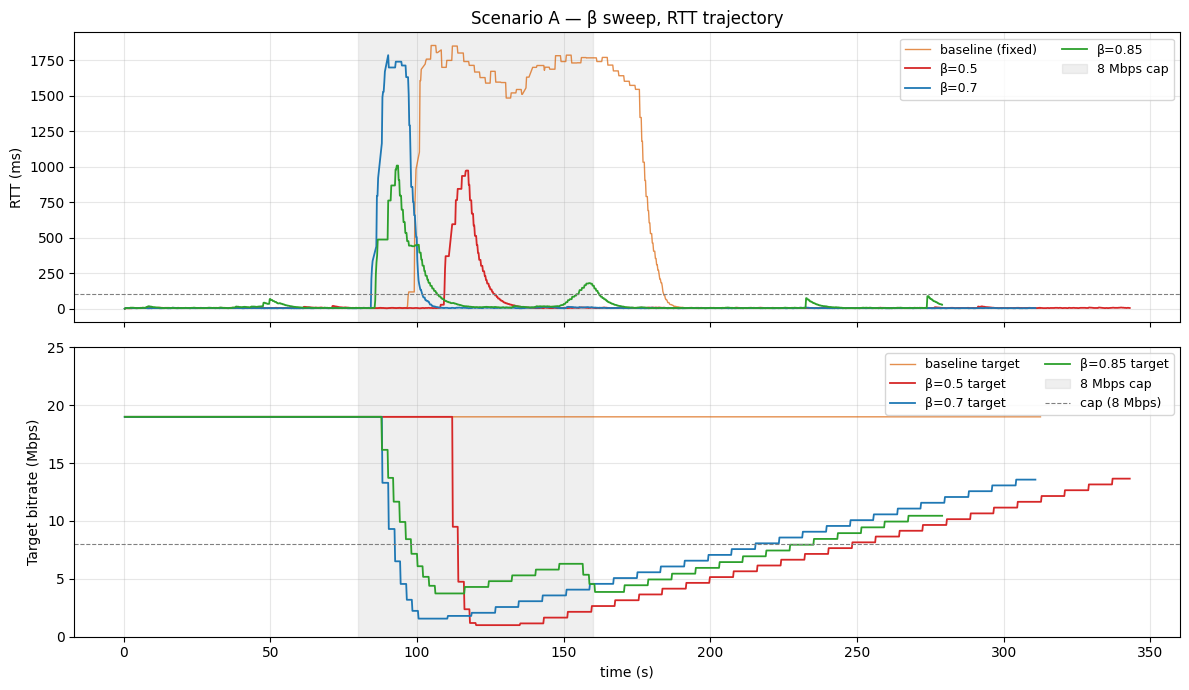

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax_rtt, ax_bw = axes

ax_rtt.plot(baseline['df']['elapsed_s'], baseline['df']['rtt_ms'],
            color=BASELINE_COLOR, label='baseline (fixed)', linewidth=1.0, alpha=0.7)
ax_bw.plot(baseline['df']['elapsed_s'], baseline['df']['target_kbps'] / 1000.0,
           color=BASELINE_COLOR, label='baseline target', linewidth=1.0, alpha=0.7)

for b in sorted(BETA_DIRS):
    df = runs[b]['df']
    ax_rtt.plot(df['elapsed_s'], df['rtt_ms'], color=BETA_COLORS[b], label=f'β={b}', linewidth=1.3)
    ax_bw.plot(df['elapsed_s'], df['target_kbps'] / 1000.0, color=BETA_COLORS[b], label=f'β={b} target', linewidth=1.3)

for ax in axes:
    ax.axvspan(CAP_START_S, CAP_END_S, color='grey', alpha=0.12, label='8 Mbps cap')
    ax.grid(alpha=0.3)
ax_rtt.axhline(RTT_THRESHOLD_MS, ls='--', lw=0.8, color='grey')
ax_rtt.set_ylabel('RTT (ms)')
ax_rtt.set_title('Scenario A — β sweep, RTT trajectory')
ax_rtt.legend(loc='upper right', fontsize=9, ncol=2)

ax_bw.axhline(CAP_MBPS, ls='--', lw=0.8, color='grey', label='cap (8 Mbps)')
ax_bw.set_ylabel('Target bitrate (Mbps)')
ax_bw.set_xlabel('time (s)')
ax_bw.set_ylim(0, 25)
ax_bw.legend(loc='upper right', fontsize=9, ncol=2)

plt.tight_layout()
plt.savefig('beta_sweep_trajectory.png', bbox_inches='tight')
plt.show()

## 3. Transient triple per β

In [5]:
def above_threshold_runs(df, threshold_ms):
    over = df['rtt_ms'] > threshold_ms
    if not over.any():
        return []
    groups = (over != over.shift()).cumsum()
    out = []
    for _, g in df[over].groupby(groups[over]):
        out.append({
            'start_s': g['elapsed_s'].iloc[0],
            'end_s':   g['elapsed_s'].iloc[-1],
            'duration_s': g['elapsed_s'].iloc[-1] - g['elapsed_s'].iloc[0],
            'peak_ms': g['rtt_ms'].max(),
            'mean_ms': g['rtt_ms'].mean(),
        })
    return out

def transient_triple(df):
    runs_ = above_threshold_runs(df, RTT_THRESHOLD_MS)
    if not runs_:
        return {'RTVL_peak_ms': 0, 'L_AP_s': 0.0, 'AP_ms': 0.0}
    main = max(runs_, key=lambda r: r['duration_s'])
    return {'RTVL_peak_ms': main['peak_ms'], 'L_AP_s': round(main['duration_s'], 1), 'AP_ms': round(main['mean_ms'], 1)}

rows = [{'run': 'baseline (fixed)', **transient_triple(baseline['df'])}]
for b in sorted(BETA_DIRS):
    rows.append({'run': f'adaptive β={b}', **transient_triple(runs[b]['df'])})

triple_df = pd.DataFrame(rows)
triple_df

,run,RTVL_peak_ms,L_AP_s,AP_ms
0,baseline (fixed),1854,86.8,1427.0
1,adaptive β=0.5,973,17.1,530.0
2,adaptive β=0.7,1786,17.3,1170.7
3,adaptive β=0.85,1008,20.7,493.4


## 4. Effective channel use during the 80–160 s shaping window

In [6]:
def channel_use(df, t0=CAP_START_S, t1=CAP_END_S, cap_mbps=CAP_MBPS):
    w = df[(df['elapsed_s'] >= t0) & (df['elapsed_s'] < t1)]
    if len(w) == 0:
        return float('nan')
    return w['bitrate_kbps'].mean() / (cap_mbps * 1000)

def stable_target(df, t0=CAP_START_S, t1=CAP_END_S):
    """Median target_kbps during the shaping window."""
    w = df[(df['elapsed_s'] >= t0) & (df['elapsed_s'] < t1)]
    return float(w['target_kbps'].median()) if len(w) else float('nan')

rows = [{
    'run': 'baseline (fixed)',
    'channel_use': round(channel_use(baseline['df']), 3),
    'median_target_kbps': stable_target(baseline['df']),
    'p95_rtt_in_window': round(baseline['df'][(baseline['df']['elapsed_s'] >= CAP_START_S) & (baseline['df']['elapsed_s'] < CAP_END_S)]['rtt_ms'].quantile(0.95), 1),
}]
for b in sorted(BETA_DIRS):
    df = runs[b]['df']
    rows.append({
        'run': f'adaptive β={b}',
        'channel_use': round(channel_use(df), 3),
        'median_target_kbps': stable_target(df),
        'p95_rtt_in_window': round(df[(df['elapsed_s'] >= CAP_START_S) & (df['elapsed_s'] < CAP_END_S)]['rtt_ms'].quantile(0.95), 1),
    })

use_df = pd.DataFrame(rows)
use_df

,run,channel_use,median_target_kbps,p95_rtt_in_window
0,baseline (fixed),1.640,18988.0,1802.2
1,adaptive β=0.5,0.650,2150.0,844.0
2,adaptive β=0.7,0.415,3066.0,1699.0
3,adaptive β=0.85,0.580,5297.0,762.0


## 5. Controller state distribution per β

In [7]:
STATE_NAMES = {0: 'stable', 1: 'congested', 2: 'decreasing', 3: 'recovering', 4: 'probing', -1: 'disabled'}

rows = []
for b in sorted(BETA_DIRS):
    df = runs[b]['df']
    counts = df['abr_state'].value_counts().to_dict()
    total = sum(counts.values())
    row = {'β': b}
    for code, name in STATE_NAMES.items():
        row[name] = round(counts.get(code, 0) / total * 100, 1) if total else 0
    rows.append(row)

state_df = pd.DataFrame(rows).set_index('β')
state_df

,stable,congested,decreasing,recovering,probing,disabled
β,,,,,,
0.50,87.6,3.1,1.5,0.3,7.5,0.1
0.70,87.2,2.2,2.2,0.7,7.6,0.1
0.85,83.6,5.1,4.6,0.8,5.8,0.1


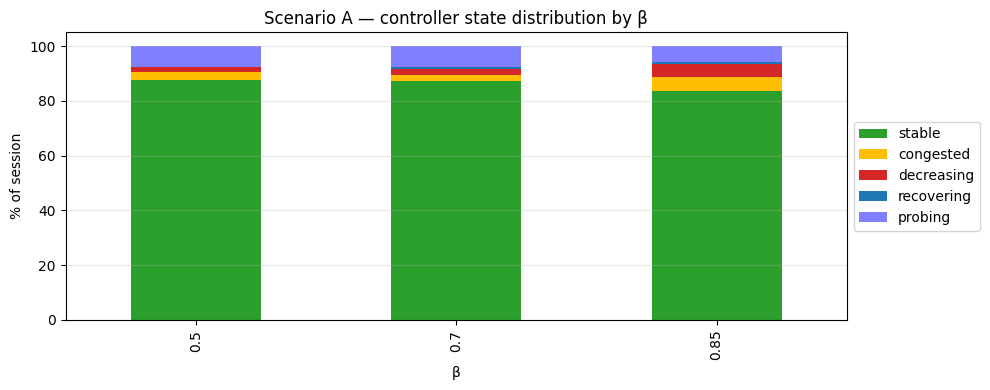

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
state_df[['stable', 'congested', 'decreasing', 'recovering', 'probing']].plot(
    kind='bar', stacked=True, ax=ax,
    color=['#2ca02c', '#ffbf00', '#d62728', '#1f78b4', '#7f7fff'],
)
ax.set_ylabel('% of session')
ax.set_title('Scenario A — controller state distribution by β')
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('beta_sweep_state_distribution.png', bbox_inches='tight')
plt.show()

## 6. Findings (auto-filled after execution)

This section is filled in by hand once the executed numbers are read. The questions to answer:

1. **RTT triple winner.** Which β minimizes L_AP and AP without inflating RTVL_peak?
2. **Channel-use winner.** Does gentler β (0.85) close the gap toward C³G? Does aggressive β (0.5) hurt it further?
3. **Subjective rating winner.** Does the operator perceive a difference between β values?
4. **Is the tradeoff smooth, or is there a sweet spot?** If 0.85 dominates 0.7 on both axes (RTT + channel use), the recommendation is to change the default. If 0.5 dominates 0.85, the conservative path was wrong. If neither dominates, there's a real tradeoff and we have to defend the choice.
5. **Where does each β land relative to C³G's 93–96 % target?** This is the headline number for the simpler-policy claim.